# Project 1: VaR and ES -- Estimation, Backtesting, and Model Comparison

**Names of all group members:**
- Firstname Lastname (email@example.com)
- Firstname Lastname (email@example.com)

---

## 0) Setup

Creates necessary folders, sets parameters, and fixes the random seed. Keep this seed fixed; the whole run must be reproducible from it.

In [1]:
# If a package import fails, install it in your environment, e.g.:
# %pip install arch statsmodels

import os
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
from pathlib import Path

PROJECT_DIR = Path.cwd()
DATA_FILE = PROJECT_DIR / "../data/QRM_2026_Project_prices.csv"   # provided with the project; do not re-download
OUT_DIR = PROJECT_DIR / "output"
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Parameters
TICKERS = ["AAPL", "META", "JPM"]   # every question is run separately on each stock
WINDOW = 504                        # estimation window of every model, in trading days (Questions 2-5)
EVAL_START = 504                    # Questions 3-5: forecast days are all days after the first 504
REFIT = 21                          # Questions 4-5: re-estimate every this many trading days
ALPHAS = [0.975, 0.99]              # confidence levels used throughout Questions 2-5
DEEP_ALPHA = 0.999                  # Question 6: the extreme level EVT is asked for
M_SIM = 10_000                      # Questions 3(c), 4(d): Acerbi-Szekely simulated samples
LB_LAGS = 10                        # Ljung-Box H in Questions 1 and 4
NW_LAGS = 10                        # Newey-West truncation lag of the Diebold-Mariano test
SEED = 0                            # fix this, state it in the report, do not change it later

rng = np.random.default_rng(SEED)
print("Project dir:", PROJECT_DIR)


Project dir: c:\Users\msaco\Documents\M2\epfl\MA3\qrm\QRM_Project\src


## 1) Data

The prices were downloaded once with `yfinance` (adjusted closes, 2 January 2013 to 30 June 2026,
downloaded on 28 October 2026) and are provided as `QRM_2026_Project_prices.csv`. Read this file;
do not download the data again, since Yahoo revises adjusted prices back in time.

In [4]:
price_df = pd.read_csv(DATA_FILE, index_col=0, parse_dates=True)[TICKERS]
print(price_df.shape, price_df.index[0].date(), "to", price_df.index[-1].date())   # (3393, 3)

(3393, 3) 2013-01-02 to 2026-06-30


## 2) Log-returns and losses

Construct $R_t=\log(P_t/P_{t-1})$ for each ticker. The log-loss used everywhere in this project is
$L_t=-R_t$. Every question is run separately on each of the three columns; there is no portfolio.

In [5]:
returns = np.log(price_df / price_df.shift(1)).dropna()
losses = -returns

print(returns.shape, returns.index[0].date(), "to", returns.index[-1].date())   # (3392, 3)
returns.head()

(3392, 3) 2013-01-03 to 2026-06-30


,AAPL,META,JPM
Date,,,
2013-01-03,-0.012703,-0.008248,-0.002017
2013-01-04,-0.028250,0.035029,0.017569
2013-01-07,-0.005900,0.022689,0.001101
2013-01-08,0.002688,-0.012312,0.001980
2013-01-09,-0.015752,0.051311,-0.000660


## Question 1 -- Stylized facts

For each stock: (a) plot the return series; (b) ACF of returns and of squared returns, and the
Ljung-Box test with $H$ = `LB_LAGS` on both (`statsmodels.stats.diagnostic.acorr_ljungbox`);
(c) QQ-plot and Jarque-Bera.

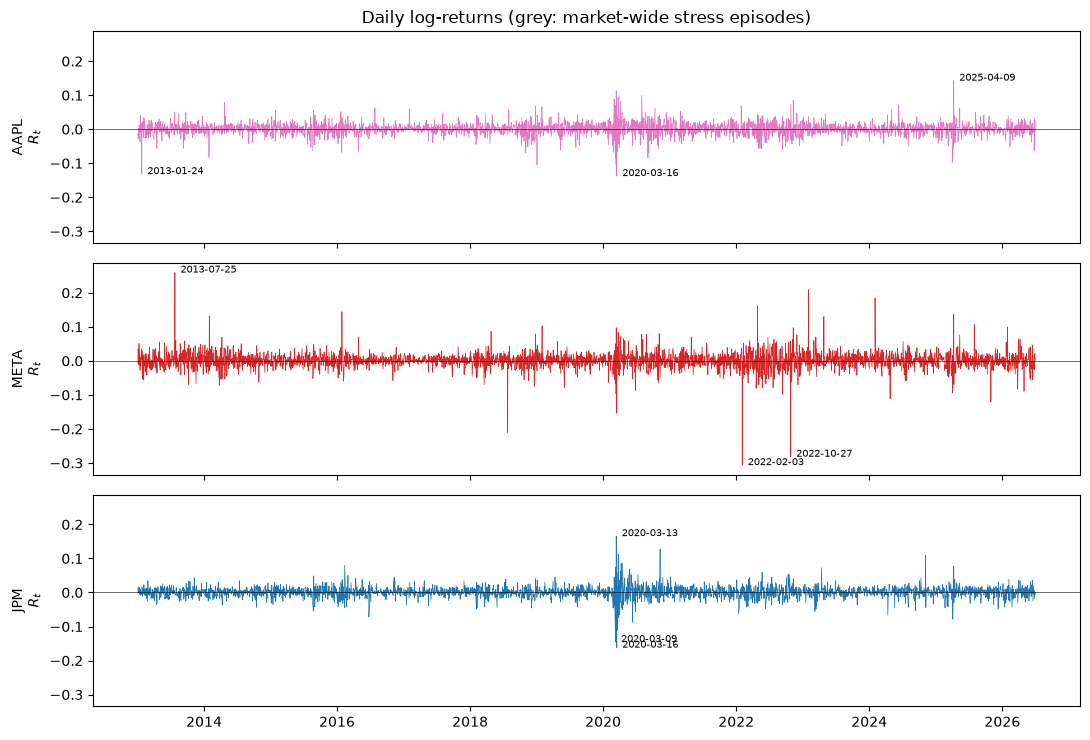

Correlation of 63-day rolling volatilities:
       AAPL  META   JPM
AAPL  1.00  0.60  0.77
META  0.60  1.00  0.47
JPM   0.77  0.47  1.00

Correlation of daily returns:
       AAPL  META   JPM
AAPL  1.00  0.46  0.39
META  0.46  1.00  0.31
JPM   0.39  0.31  1.00

Top-5 moves of AAPL (in %, all three stocks that day):
             AAPL   META    JPM
Date                           
2025-04-09  14.26  13.76   7.75
2020-03-16 -13.77 -15.38 -16.21
2013-01-24 -13.19   0.84   0.30
2020-03-13  11.32   9.74  16.56
2019-01-03 -10.49  -2.95  -1.43

Top-5 moves of META (in %, all three stocks that day):
            AAPL   META   JPM
Date                         
2022-02-03 -1.69 -30.64 -0.83
2022-10-27 -3.09 -28.18  0.39
2013-07-25 -0.46  25.94 -0.23
2018-07-26 -0.31 -21.02 -0.29
2023-02-02  3.64  20.93 -0.47

Top-5 moves of JPM (in %, all three stocks that day):
             AAPL   META    JPM
Date                           
2020-03-13  11.32   9.74  16.56
2020-03-16 -13.77 -15.38 -16.21
2020-03-09

In [ ]:
# Question 1
# (a)
colors = {"AAPL": "tab:pink", "META": "tab:red", "JPM": "tab:blue"}


fig, axes = plt.subplots(3, 1, figsize=(11, 7.5), sharex=True, sharey=True)
for ax, tic in zip(axes, TICKERS):
    ax.plot(returns.index, returns[tic], lw=0.5, color=colors[tic])
    ax.axhline(0, color="black", lw=0.4)
    ax.set_ylabel(f"{tic}\n$R_t$")
    for d in returns[tic].abs().nlargest(3).index:          
        ax.annotate(d.strftime("%Y-%m-%d"), (d, returns.loc[d, tic]),
                    fontsize=7, xytext=(4, 0), textcoords="offset points")
axes[0].set_title("Daily log-returns")
plt.tight_layout()
plt.savefig(OUT_DIR / "fig_q1a_returns.png", dpi=200)
plt.show()

roll_vol = returns.rolling(63).std() * np.sqrt(252)         
print("Correlation of 63-day rolling volatilities:\n", roll_vol.corr().round(2))
print("\nCorrelation of daily returns:\n", returns.corr().round(2))
for tic in TICKERS:                                          
    top = returns[tic].abs().nlargest(5).index
    print(f"\nTop-5 moves of {tic} (in %, all three stocks that day):")
    print((100 * returns.loc[top]).round(2).to_string())

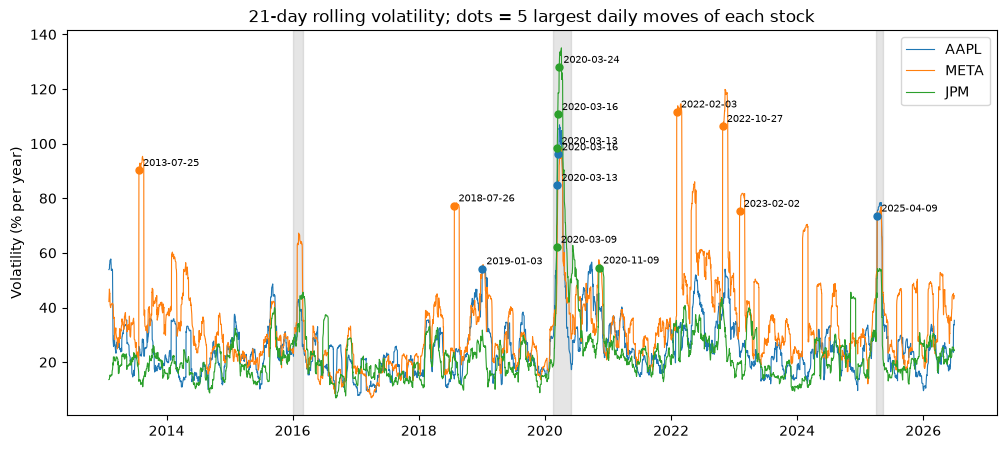


5 largest moves of AAPL (returns in %):
            AAPL  META   JPM
Date                        
2025-04-09  14.3  13.8   7.7
2020-03-16 -13.8 -15.4 -16.2
2013-01-24 -13.2   0.8   0.3
2020-03-13  11.3   9.7  16.6
2019-01-03 -10.5  -2.9  -1.4

5 largest moves of META (returns in %):
            AAPL  META  JPM
Date                       
2022-02-03  -1.7 -30.6 -0.8
2022-10-27  -3.1 -28.2  0.4
2013-07-25  -0.5  25.9 -0.2
2018-07-26  -0.3 -21.0 -0.3
2023-02-02   3.6  20.9 -0.5

5 largest moves of JPM (returns in %):
            AAPL  META   JPM
Date                        
2020-03-13  11.3   9.7  16.6
2020-03-16 -13.8 -15.4 -16.2
2020-03-09  -8.2  -6.6 -14.6
2020-11-09  -2.0  -5.1  12.7
2020-03-24   9.6   8.3  11.2


In [ ]:
# Question 1 (a) 

vol = returns.rolling(21).std() * np.sqrt(252) * 100
colors = {"AAPL": "tab:blue", "META": "tab:orange", "JPM": "tab:green"}

plt.figure(figsize=(12, 5))

plt.axvspan(pd.Timestamp("2016-01-01"), pd.Timestamp("2016-02-29"), color="grey", alpha=0.2)
plt.axvspan(pd.Timestamp("2020-02-20"), pd.Timestamp("2020-05-31"), color="grey", alpha=0.2)
plt.axvspan(pd.Timestamp("2025-04-01"), pd.Timestamp("2025-05-15"), color="grey", alpha=0.2)

for tic in TICKERS:
    #The volatility curve
    plt.plot(vol.index, vol[tic], label=tic, lw=0.8, color=colors[tic])

    #The 5 days with the largest move (in absolute value)
    big_days = returns[tic].abs().sort_values(ascending=False).head(5).index
    for day in big_days:
        plt.scatter(day, vol.loc[day, tic], color=colors[tic], s=25, zorder=3)
        plt.annotate(day.strftime("%Y-%m-%d"), (day, vol.loc[day, tic]),
                     fontsize=7, xytext=(3, 3), textcoords="offset points")

plt.ylabel("Volatility (% per year)")
plt.title("21-day rolling volatility; dots = 5 largest daily moves of each stock")
plt.legend()
plt.savefig(OUT_DIR / "fig_q1a_vol.png", dpi=200)
plt.show()

#Big days with the return of the three stocks that day (in %)
for tic in TICKERS:
    big_days = returns[tic].abs().sort_values(ascending=False).head(5).index
    print(f"\n5 largest moves of {tic} (returns in %):")
    print((returns.loc[big_days] * 100).round(1))

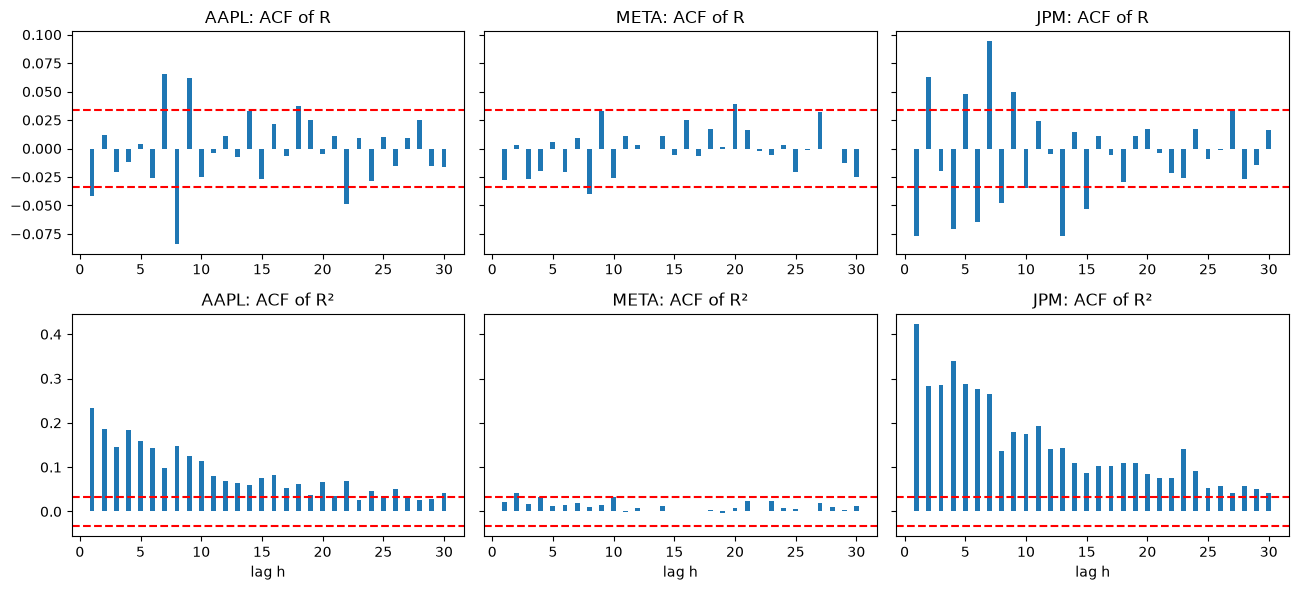

          Q (R)  p-value (R)     Q (R²)  p-value (R²)
stock                                                
AAPL    64.4300       0.0000   849.2934         0.000
META    19.5762       0.0335    19.0975         0.039
JPM    124.2931       0.0000  2607.4927         0.000


In [ ]:
# Question 1 (b) 
from statsmodels.tsa.stattools import acf
from statsmodels.stats.diagnostic import acorr_ljungbox

n = len(returns)
band = 1.96 / np.sqrt(n)          # 95% band if the data were i.i.d.
lags = range(1, 31)               # lags 1, 2, ..., 30

fig, axes = plt.subplots(2, 3, figsize=(13, 6), sharey="row")

for i, tic in enumerate(TICKERS):
    r = returns[tic]
    r2 = r ** 2

    # ACF of the returns
    acf_r = acf(r, nlags=30)[1:]          # [1:] removes lag 0 (always 1)
    axes[0, i].bar(lags, acf_r, width=0.4)
    axes[0, i].axhline(band, color="red", ls="--")
    axes[0, i].axhline(-band, color="red", ls="--")
    axes[0, i].set_title(f"{tic}: ACF of R")

    # ACF of the squared returns
    acf_r2 = acf(r2, nlags=30)[1:]
    axes[1, i].bar(lags, acf_r2, width=0.4)
    axes[1, i].axhline(band, color="red", ls="--")
    axes[1, i].axhline(-band, color="red", ls="--")
    axes[1, i].set_title(f"{tic}: ACF of R²")
    axes[1, i].set_xlabel("lag h")

plt.tight_layout()
plt.savefig(OUT_DIR / "fig_q1b_acf.png", dpi=200)
plt.show()

# Ljung-Box test with H = 10
print("Ljung-Box test results")
results = []
for tic in TICKERS:
    r = returns[tic]
    lb_r = acorr_ljungbox(r, lags=[LB_LAGS])
    lb_r2 = acorr_ljungbox(r ** 2, lags=[LB_LAGS])
    results.append({"stock": tic,
                    "Q (R)": lb_r["lb_stat"].iloc[0],
                    "p-value (R)": lb_r["lb_pvalue"].iloc[0],
                    "Q (R²)": lb_r2["lb_stat"].iloc[0],
                    "p-value (R²)": lb_r2["lb_pvalue"].iloc[0]})

lb_table = pd.DataFrame(results).set_index("stock")
print(lb_table.round(4))

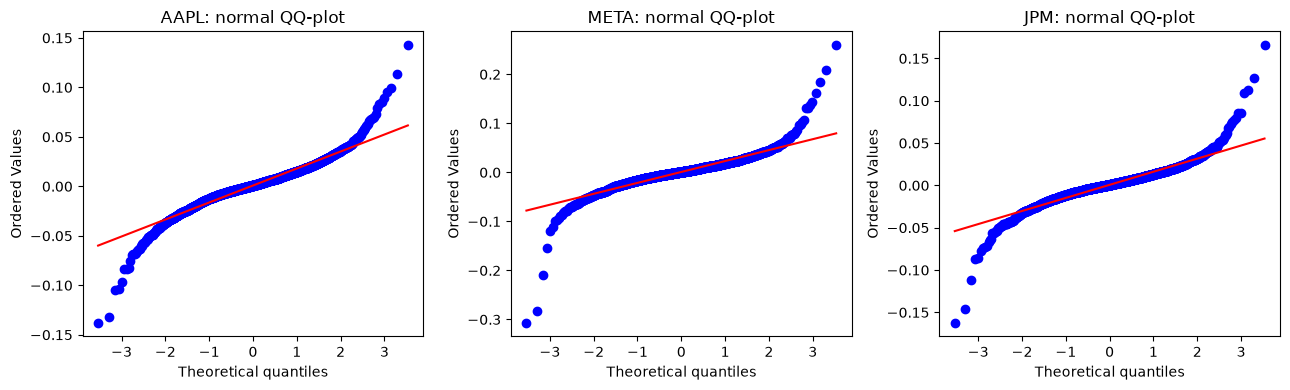

       skewness  kurtosis          JB  p-value
stock                                         
AAPL    -0.2247    9.8139   6590.6140      0.0
META    -0.4974   27.3901  84216.0510      0.0
JPM     -0.0843   15.9363  23655.8191      0.0


In [12]:
# Question 1 (c) 

fig, axes = plt.subplots(1, 3, figsize=(13, 4))

for i, tic in enumerate(TICKERS):
    r = returns[tic]
    stats.probplot(r, dist="norm", plot=axes[i])   # QQ-plot against the normal
    axes[i].set_title(f"{tic}: normal QQ-plot")

plt.tight_layout()
plt.savefig(OUT_DIR / "fig_q1c_qq.png", dpi=200)
plt.show()

# Jarque-Bera test + skewness and kurtosis
results = []
for tic in TICKERS:
    r = returns[tic]
    jb_stat, jb_pvalue = stats.jarque_bera(r)
    results.append({"stock": tic,
                    "skewness": stats.skew(r),
                    "kurtosis": stats.kurtosis(r, fisher=False),   # normal = 3
                    "JB": jb_stat,
                    "p-value": jb_pvalue})

jb_table = pd.DataFrame(results).set_index("stock")
print(jb_table.round(4))

## Question 2 -- Single-window VaR and ES estimates

For each stock, use the first `WINDOW` losses as the single estimation window for (a)-(d).

In [ ]:
# Question 2
window_loss = losses.iloc[:WINDOW]          # one column per stock
W = len(window_loss)                        
print("Window:", window_loss.index[0].date(), "to", window_loss.index[-1].date())


# Historical simulation
def hs_var_es(L, alpha):
    L_sorted = np.sort(L)[::-1]                 # largest loss first
    k = int(np.floor(W * (1 - alpha)))         
    var = L_sorted[k]                           
    es = (L_sorted[:k].sum() + (W * (1 - alpha) - k) * L_sorted[k]) / (W * (1 - alpha))
    return var, es

Window: 2013-01-03 to 2015-01-02

Fitted parameters:
        mu_n  sigma_n      nu    mu_t  sigma_t    sd_t
AAPL -0.0007   0.0160  4.1324 -0.0011   0.0111  0.0155
META -0.0020   0.0251  4.6793 -0.0013   0.0178  0.0235
JPM  -0.0008   0.0116  6.4827 -0.0010   0.0097  0.0117

VaR (%):
stock            AAPL  META   JPM
alpha method                     
0.975 Gaussian   3.07  4.72  2.20
      HS         2.90  4.23  2.38
      Student-t  2.95  4.54  2.24
0.990 Gaussian   3.65  5.64  2.62
      HS         3.89  5.35  2.78
      Student-t  3.99  6.03  2.89

ES (%):
stock            AAPL  META   JPM
alpha method                     
0.975 Gaussian   3.67  5.67  2.64
      HS         4.97  5.60  2.92
      Student-t  4.25  6.35  2.99
0.990 Gaussian   4.20  6.49  3.02
      HS         7.39  6.53  3.54
      Student-t  5.56  8.14  3.69


In [ ]:
# Gaussian 
def normal_var_es(mu, sigma, alpha):
    z = stats.norm.ppf(alpha)                  
    var = mu + sigma * z
    es = mu + sigma * stats.norm.pdf(z) / (1 - alpha)
    return var, es

In [ ]:
# Student-t
def t_var_es(nu, mu, sigma, alpha):
    q = stats.t.ppf(alpha, nu)                  # quantile of the standard t_nu
    var = mu + sigma * q
    es = mu + sigma * stats.t.pdf(q, nu) / (1 - alpha) * (nu + q**2) / (nu - 1)
    return var, es


def fit_t(L):
    """ML fit of (nu, mu, sigma) from several starting values of nu; keep the best."""
    best = None
    for nu_start in [2.5, 4, 6, 10, 30]:
        nu, mu, sigma = stats.t.fit(L, nu_start, loc=np.median(L), scale=np.std(L))
        loglik = stats.t.logpdf(L, nu, mu, sigma).sum()
        if best is None or loglik > best[3]:
            best = (nu, mu, sigma, loglik)
    return best

In [ ]:
# Compute VaR and ES for every alpha and with every method
rows = []        # VaR / ES results
params = {}      # fitted parameters

for tic in TICKERS:
    L = window_loss[tic].values

    mu_n = L.mean()
    sigma_n = L.std(ddof=1)
    nu, mu_t, sigma_t, loglik = fit_t(L)
    params[tic] = {"mu_n": mu_n, "sigma_n": sigma_n,
                   "nu": nu, "mu_t": mu_t, "sigma_t": sigma_t}

    for alpha in ALPHAS:
        var, es = hs_var_es(L, alpha)
        rows.append({"stock": tic, "alpha": alpha, "method": "HS", "VaR": var, "ES": es})
        var, es = normal_var_es(mu_n, sigma_n, alpha)
        rows.append({"stock": tic, "alpha": alpha, "method": "Gaussian", "VaR": var, "ES": es})
        var, es = t_var_es(nu, mu_t, sigma_t, alpha)
        rows.append({"stock": tic, "alpha": alpha, "method": "Student-t", "VaR": var, "ES": es})

q2 = pd.DataFrame(rows)

# Fitted parameters
param_table = pd.DataFrame(params).T
param_table["sd_t"] = param_table["sigma_t"] * np.sqrt(param_table["nu"] / (param_table["nu"] - 2))
print("\nFitted parameters:")
print(param_table.round(4))

# VaR and ES tables, in %, the three stocks side by side
print("\nVaR (%):")
print((100 * q2.pivot_table(index=["alpha", "method"], columns="stock", values="VaR")[TICKERS]).round(2))
print("\nES (%):")
print((100 * q2.pivot_table(index=["alpha", "method"], columns="stock", values="ES")[TICKERS]).round(2))


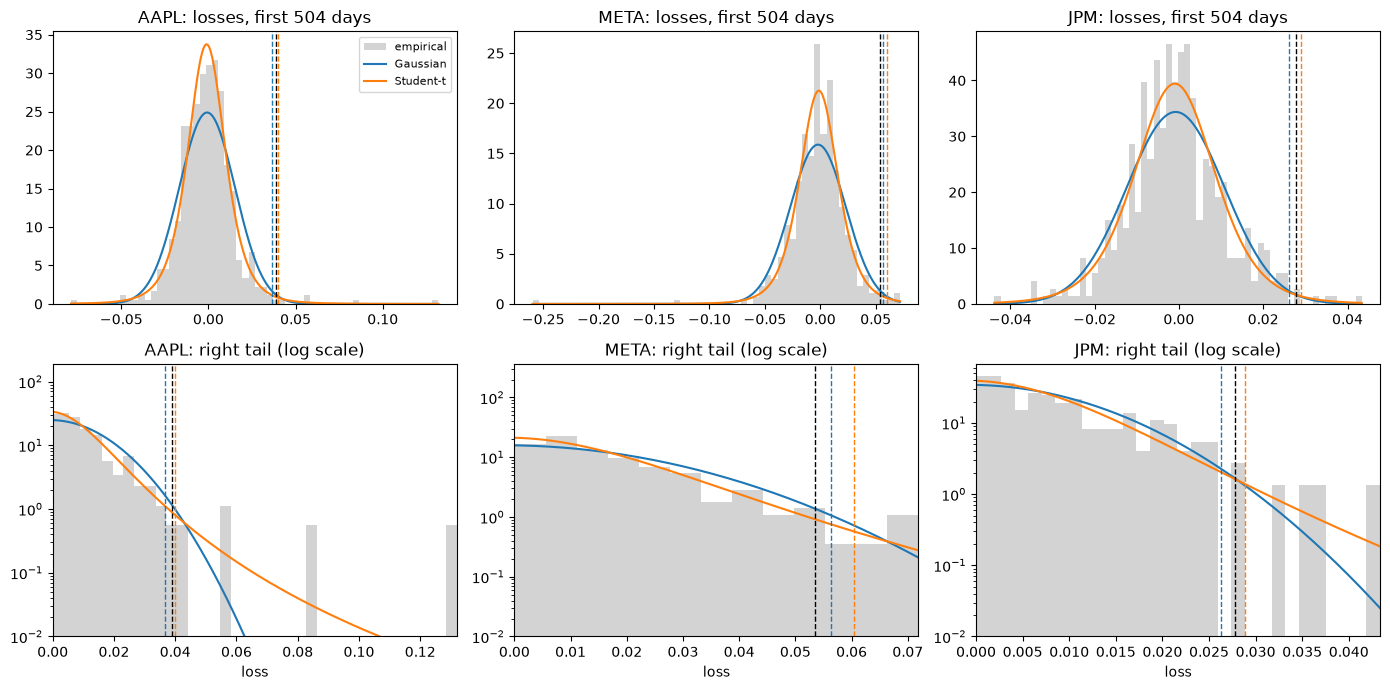

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for i, tic in enumerate(TICKERS):
    L = window_loss[tic].values
    p = params[tic]
    x = np.linspace(L.min(), L.max(), 500)

    for row in [0, 1]:
        ax = axes[row, i]
        ax.hist(L, bins=60, density=True, color="lightgrey", label="empirical")
        ax.plot(x, stats.norm.pdf(x, p["mu_n"], p["sigma_n"]), label="Gaussian")
        ax.plot(x, stats.t.pdf(x, p["nu"], p["mu_t"], p["sigma_t"]), label="Student-t")

        # VaR at 99% of the three methods
        for method, color in [("HS", "black"), ("Gaussian", "tab:red"), ("Student-t", "tab:green")]:
            v = q2[(q2.stock == tic) & (q2.alpha == 0.99) & (q2.method == method)]["VaR"].iloc[0]
            ax.axvline(v, color=color, ls="--", lw=1)

    axes[0, i].set_title(f"{tic}: losses, first {W} days")
    axes[1, i].set_yscale("log")                
    axes[1, i].set_xlim(0, L.max())             
    axes[1, i].set_title(f"{tic}: right tail (log scale)")
    axes[1, i].set_xlabel("loss")
    axes[1, i].set_ylim(1e-2, None)             

axes[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.savefig(OUT_DIR / "fig_q2_densities.png", dpi=200)
plt.show()

## Question 3 -- Backtesting

Forecast every day of the evaluation period `losses.iloc[EVAL_START:]`, each model estimated on the
`WINDOW` days before the forecast day. Historical simulation, Gaussian and Student-$t$ are recomputed
every day. Write the Kupiec, Christoffersen, Acerbi-Szekely, Fissler-Ziegel, pinball-loss and
Diebold-Mariano functions yourself, from the course slides (Kupiec, Christoffersen) and Appendix A of
the project statement (the others); they are
reused unchanged in Questions 4 and 5.

The combined VaR backtest table collects the VaR backtests of Questions 3-5: append one row per
stock, method and level to `backtest_rows` as you go. The ES backtest table ($\alpha=0.975$) collects
the Acerbi-Szekely and Fissler-Ziegel results of Questions 3 and 4 in `es_rows`.

In [ ]:
# Question 3
eval_loss = losses.iloc[EVAL_START:]        # one column per stock, 2888 forecast days
backtest_rows = []                          # dicts: stock, method, alpha, x, expected, hit, p_uc, p_ind, p_cc, pinball_bp
es_rows = []                                # dicts: stock, method, Z, p_Z, FZ


## Question 4 -- AR-GARCH conditional VaR and ES

(a) Mean model, full sample: fit AR($p$), $p=0,\dots,3$, with constant variance on the same
observations, e.g. `ARX(y, lags=p, hold_back=3)` from `arch.univariate`; pick $p$ by BIC (also report
AIC); Ljung-Box on the residuals (`model_df=p`) and on their squares.
(b) Fit `arch_model(y, mean="AR", lags=p, vol="GARCH", p=1, q=1, dist=..., hold_back=3)` on the full
sample with `dist="normal"` and `dist="t"` (use `mean="Constant"` if $p=0$); Ljung-Box on the
standardized residuals of the Gaussian fit (`model_df=p`) and their squares (`model_df=2`).
(c) Re-estimate both inside the rolling scheme every `REFIT` days with the same $p$. Between refits,
keep the parameters fixed but advance $\hat\mu_t$ and $\hat\sigma_t$ daily with the realized
returns (for example with `arch_model(...).fix(params)` on the data up to the forecast day). Fit on
returns in percent (`100 * R`) to avoid `arch` convergence warnings, and convert the forecasts back.
(d) Backtest both and add them to the two tables.

In [ ]:
# Question 4
from arch import arch_model


## Question 5 -- Quantile regression

Same evaluation period, window and refit days as Question 4. One model per stock and level, VaR only;
the two features are built by `make_features` below, both using information up to $t-1$; the target
is the loss $L_t$. Rows with an undefined feature (the first 20 days) are dropped from the training
window. Linear quantile regression, e.g.
`sm.QuantReg(y, sm.add_constant(X)).fit(q=alpha, max_iter=5000)`.

In [ ]:
# Question 5
import statsmodels.api as sm


def make_features(ret: pd.Series) -> pd.DataFrame:
    """Features x_{t-1} for the forecast of day t: row t uses information up to t-1 only."""
    feat = pd.DataFrame(index=ret.index)
    feat["absR_lag1"] = ret.shift(1).abs()
    feat["sigma20"] = ret.shift(1).rolling(20).std(ddof=1)
    return feat


# After (a) and (b): the combined VaR backtest table, one table per level
# backtest_table = pd.DataFrame(backtest_rows).set_index(["alpha", "stock", "method"]).sort_index()


## Question 6 -- Extreme value theory

One static fit on each stock's full-sample log-loss series, with threshold $u$ the empirical 95%
quantile. `scipy.stats.genpareto.fit(excesses, floc=0)` may be used for the GPD maximum-likelihood
step.

In [ ]:
# Question 6
from scipy.stats import genpareto
full_loss = losses                          # one column per stock
